# Contextual shot explorer

## Goal

Inspect **actual saved shots**, their freeze frames and the exact features supplied to the contextual xG
models. Use the match, team, player and outcome selectors to find a shot, inspect any of the eight feature
groups, and compare two observed situations side by side.

The starting example is **Chelsea–Tottenham, May 2, 2016**. Harry Kane's goal at 34:29 has model xG
**0.906**. Heung-Min Son's blocked shot at 39:13, from just **0.7 pitch units** away and also taken with
the left foot, has model xG **0.201**. The frozen features record zero and two visible defenders in the
shot cone respectively. Other inputs also differ, so this is an observational comparison rather than an
estimate of a defender's causal effect.

The browser covers all **6,868 non-penalty test shots in 273 matches**. It uses frozen forecasts and
stage-8 features, downloads public event labels only for the match you load, and does not train models.
Saved static examples remain readable without a live widget renderer.

## Setup

Choose a **Colab Python kernel**. CPU is sufficient; your existing GPU kernel also works.
Run the cells in order. Required packages are `numpy`, `pandas`, `pyarrow`, `matplotlib`, `requests`
and IPython. For the selectors, also install `ipywidgets` if your kernel does not already provide it:

```python
%pip install numpy pandas pyarrow matplotlib requests ipywidgets
```

The original artifact directory is `/content/drive/MyDrive/xg-python`. Update `ARTIFACT_ROOT` or set
`CONTEXTUAL_XG_ARTIFACT_ROOT` for a local copy with the same directory layout. This notebook is
independent of the training notebook and the match-report notebook.

In [1]:
import gzip
import hashlib
import html
import json
import os
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Arc, Circle, Polygon, Rectangle
import numpy as np
import pandas as pd
import requests
from IPython import get_ipython
from IPython.display import Markdown, display

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")

plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 180, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.facecolor": "white", "figure.facecolor": "white",
    "text.color": "#172033", "axes.labelcolor": "#334155",
})
COMMIT = "3bfbffe1de5750ebd47d770be0bb924a10cde54f"
DEFAULT_MATCH_ID = 3754092
ARTIFACT_ROOT = Path(os.environ.get(
    "CONTEXTUAL_XG_ARTIFACT_ROOT", "/content/drive/MyDrive/xg-python"
)).expanduser()
CACHE_DIR = Path(os.environ.get(
    "CONTEXTUAL_XG_MATCH_CACHE", str(Path(tempfile.gettempdir()) / "contextual-xg-match-analysis")
)) / COMMIT
if str(ARTIFACT_ROOT).startswith("/content/drive/") and not Path("/content/drive/MyDrive").is_dir():
    from google.colab import drive
    drive.mount("/content/drive")
CACHE_DIR.mkdir(parents=True, exist_ok=True)
FINAL_RELATIVE = Path("models") / COMMIT / "final_evaluation"
PROCESSED_RELATIVE = Path("data/processed") / COMMIT
BASE_MODEL_ORDER = ["logistic_regression", "gam", "xgboost", "extra_trees"]
MODEL_LABELS = {
    "stack_identity": "Selected stack", "benchmark_statsbomb_xg": "StatsBomb benchmark",
    "logistic_regression": "Logistic regression", "gam": "GAM",
    "xgboost": "XGBoost", "extra_trees": "Extra Trees",
}


### Verify the frozen inputs

Read the original manifest, test predictions, match metadata and stage-8 checkpoint. Each data file
is checked against its frozen SHA-256. There is no fallback to a different model or dataset.
Only test rows are loaded from the feature table. No model files or GPU inference are needed.

In [2]:
def sha256_file(path):
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()

def require_file(relative, expected_hash=None):
    path = ARTIFACT_ROOT / relative
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path}. Mount Drive or update ARTIFACT_ROOT to the original xg-python project.")
    if expected_hash is not None and sha256_file(path) != expected_hash:
        raise ValueError(f"Frozen artifact hash mismatch: {relative}")
    return path

result_path = require_file(FINAL_RELATIVE / "test_result.json")
test_result = json.loads(result_path.read_text())
manifest_path = require_file(FINAL_RELATIVE / "frozen_manifest.json", test_result["frozen_manifest_sha256"])
manifest = json.loads(manifest_path.read_text())
if (manifest["data_source"] != {"repository":"hudl/open-data", "commit":COMMIT}
        or manifest["selected_model"] != "stack_identity"
        or manifest["stack_model_order"] != BASE_MODEL_ORDER
        or manifest["calibration"]["method"] != "identity"):
    raise ValueError("Expected the original pinned stack with identity calibration.")

prediction_relative = test_result["artifacts"]["test_model_predictions.parquet"]
prediction_path = require_file(prediction_relative, test_result["artifact_sha256"][prediction_relative])
feature_relative = (PROCESSED_RELATIVE / "features_stage_08.parquet").as_posix()
registry_relative = (PROCESSED_RELATIVE / "features_stage_08.json").as_posix()
feature_path = require_file(feature_relative, manifest["files"][feature_relative]["sha256"])
registry_path = require_file(registry_relative, manifest["files"][registry_relative]["sha256"])
matches_path = require_file("matches.parquet", manifest["files"]["matches.parquet"]["sha256"])
FEATURE_GROUPS = json.loads(registry_path.read_text())["feature_groups"]
raw_features = [f for group in FEATURE_GROUPS.values() for f in group]
if len(FEATURE_GROUPS) != 8 or len(raw_features) != 67 or len(set(raw_features)) != 67:
    raise ValueError("Expected eight ordered feature groups and 67 distinct raw features.")
if set(raw_features) & {"is_goal", "shot_id", "match_id", "split", "benchmark_statsbomb_xg"}:
    raise ValueError("The feature registry contains a forbidden predictor.")

predictions = pd.read_parquet(prediction_path)
features = pd.read_parquet(feature_path, filters=[("split", "==", "test")])
matches = pd.read_parquet(matches_path)
for frame in (predictions, features):
    if frame["shot_id"].isna().any() or not frame["shot_id"].is_unique or not frame["split"].eq("test").all():
        raise ValueError("Test shot IDs or split labels are invalid.")
if (len(predictions) != manifest["evaluation_protocol"]["expected_test_shots"]
        or set(predictions["shot_id"]) != set(features["shot_id"])
        or not set(raw_features).issubset(features.columns)):
    raise ValueError("Saved predictions and feature coverage differ.")
routing = features.set_index("shot_id")["match_id"]
if not predictions["shot_id"].map(routing).eq(predictions["match_id"]).all():
    raise ValueError("Prediction and feature match routing disagree.")
probability_columns = [*BASE_MODEL_ORDER, "stack_identity"]
values = predictions[probability_columns].to_numpy(dtype=float)
if not np.isfinite(values).all() or ((values < 0) | (values > 1)).any():
    raise ValueError("Invalid saved model probabilities.")
all_shots = features.merge(
    predictions[["shot_id", *probability_columns]], on="shot_id", validate="one_to_one"
).set_index("shot_id", drop=False)
if not matches["match_id"].is_unique:
    raise ValueError("Duplicate match metadata.")
match_catalog = matches.loc[matches["match_id"].isin(all_shots["match_id"])].sort_values(
    ["match_date", "competition_id", "match_id"]
).set_index("match_id", drop=False)
if len(match_catalog) != manifest["evaluation_protocol"]["expected_test_matches"]:
    raise ValueError("Test match metadata is incomplete.")
if not match_catalog["split"].eq("test").all():
    raise ValueError("The match catalogue includes non-test matches.")
print(f"Verified {len(all_shots):,} test shots, {len(match_catalog)} matches and {len(raw_features)} raw predictors.")


Verified 6,868 test shots, 273 matches and 67 raw predictors.


## Steps

### Load a match and recover event labels

Match loading is explicit. Only the selected match's public events are requested and cached under the
pinned commit. Names, outcomes, locations and freeze frames must agree with the frozen checkpoint.
The assisting pass uses the shot's explicit `key_pass_id` and must precede the shot in the same team and period.

In [3]:
_match_cache = {}
_event_cache = {}

def clock_seconds(timestamp):
    h, m, s = timestamp.split(":")
    return int(h) * 3600 + int(m) * 60 + float(s)

def clock_label(row):
    seconds = int(clock_seconds(row["timestamp"]))
    minute, second = divmod(seconds, 60)
    base = 45 * (int(row["period"]) - 1)
    return f"{base+45}+{minute-45}:{second:02d}" if minute >= 45 else f"{base+minute}:{second:02d}"

def decode_frame(value):
    return json.loads(value) if isinstance(value, str) else None

def load_match(match_id):
    match_id = int(match_id)
    if match_id not in match_catalog.index:
        raise ValueError("Choose a match from the original test catalogue.")
    if match_id in _match_cache:
        return _match_cache[match_id].copy()
    cache = CACHE_DIR / f"events-{match_id}.json.gz"
    if cache.is_file():
        with gzip.open(cache, "rt", encoding="utf-8") as stream:
            events = json.load(stream)
    else:
        url = f"https://raw.githubusercontent.com/hudl/open-data/{COMMIT}/data/events/{match_id}.json"
        response = requests.get(url, timeout=(15,60))
        response.raise_for_status()
        events = response.json()
        if not isinstance(events, list) or not events:
            raise ValueError("Missing or invalid public events.")
        temporary = cache.with_name(cache.name + ".part")
        try:
            with gzip.open(temporary, "wt", encoding="utf-8") as stream:
                json.dump(events, stream, separators=(",",":"))
            temporary.replace(cache)
        finally:
            temporary.unlink(missing_ok=True)
    lookup = {event["id"]: event for event in events}
    if len(lookup) != len(events):
        raise ValueError("Duplicate public event IDs.")
    rows = all_shots.loc[all_shots["match_id"].eq(match_id)].copy().sort_values("event_index")
    raw_ids = {e["id"] for e in events if e["type"]["name"] == "Shot" and e["shot"]["type"]["name"] != "Penalty"}
    if raw_ids != set(rows.index):
        raise ValueError("Public non-penalty shots and frozen predictions have different IDs.")
    for row in rows.to_dict("records"):
        event = lookup[row["shot_id"]]
        if (event["team"]["id"] != row["team_id"] or event["period"] != row["period"]
                or event["index"] != row["event_index"]
                or (event["shot"]["outcome"]["name"] == "Goal") != bool(row["is_goal"])):
            raise ValueError("Event routing or outcomes differ from the frozen checkpoint.")
        np.testing.assert_array_equal(event["location"][:2], [row["shot_x"],row["shot_y"]])
        np.testing.assert_array_equal(event["shot"]["statsbomb_xg"], row["benchmark_statsbomb_xg"])
        if event["shot"].get("freeze_frame") != decode_frame(row["freeze_frame_json"]):
            raise ValueError("Freeze frames differ from the checkpoint used by the model.")
        saved_key = row["key_pass_id"] if isinstance(row["key_pass_id"], str) else None
        if saved_key != event["shot"].get("key_pass_id"):
            raise ValueError("Assisting-pass references differ from the checkpoint.")
        if saved_key:
            linked = lookup.get(saved_key)
            if (linked is None or linked["type"]["name"] != "Pass"
                    or linked["team"]["id"] != row["team_id"] or linked["period"] != row["period"]
                    or linked["index"] >= row["event_index"]):
                raise ValueError("The explicitly linked pass fails routing or time checks.")
    rows["team"] = [lookup[s]["team"]["name"] for s in rows.index]
    rows["player"] = [lookup[s].get("player",{}).get("name","Unknown player") for s in rows.index]
    rows["outcome"] = [lookup[s]["shot"]["outcome"]["name"] for s in rows.index]
    rows["clock"] = [clock_label(row) for row in rows.to_dict("records")]
    _event_cache[match_id] = lookup
    _match_cache[match_id] = rows
    return rows.copy()

def get_shot(shot_id):
    if shot_id not in all_shots.index:
        raise KeyError("Unknown test shot_id. Use load_match() to list available shots.")
    return load_match(int(all_shots.at[shot_id,"match_id"])).loc[shot_id].copy()

def match_label(match_id):
    row = match_catalog.loc[int(match_id)]
    return f"{pd.Timestamp(row['match_date']).date()} | {row['league']} | {row['home_team']} v {row['away_team']}"

match_shots = load_match(DEFAULT_MATCH_ID)
DEFAULT_SHOT_ID = str(match_shots["stack_identity"].idxmax())
print(match_label(DEFAULT_MATCH_ID))
print(f"Loaded and checked {len(match_shots)} shots. Default selection: {DEFAULT_SHOT_ID}")
display(match_shots[["clock","team","player","outcome","body_part","stack_identity"]].head(12).round(3))


2016-05-02 | Premier League | Chelsea v Tottenham Hotspur
Loaded and checked 29 shots. Default selection: 18d44868-eb7b-42ff-89ae-686983fc34fa


,clock,team,player,outcome,body_part,stack_identity
shot_id,,,,,,
22d0ef5a-1e6c-4d99-9e9e-2ce10d21cf49,3:47,Chelsea,Gary Cahill,Off T,Head,0.046
17bd9a23-0cd6-4c56-ac17-67d0e0674154,10:18,Tottenham Hotspur,Danny Rose,Off T,Left Foot,0.029
ec867dc0-85bc-42b5-9b23-f81af9a37d1f,11:19,Tottenham Hotspur,Christian Dannemann Eriksen,Blocked,Right Foot,0.032
54f40e6f-78ef-49ca-a34a-03555f7e1482,15:10,Chelsea,Francesc Fàbregas i Soler,Blocked,Right Foot,0.030
2fed936a-8eec-4b52-8821-8f793a397adc,23:34,Tottenham Hotspur,Heung-Min Son,Blocked,Left Foot,0.039
3bd7bc7c-0ea8-4a9d-94d8-e3e15fe55b24,23:58,Tottenham Hotspur,Christian Dannemann Eriksen,Off T,Right Foot,0.016
d0d494d8-29d7-4f4e-8819-500117a48d55,26:06,Chelsea,Francesc Fàbregas i Soler,Off T,Right Foot,0.071
ae70b721-1e93-4857-8c3a-b5173a6b6b23,27:17,Tottenham Hotspur,Heung-Min Son,Off T,Left Foot,0.126
26a215fc-b6fb-4fc7-90ab-71726073e8c6,29:19,Tottenham Hotspur,Harry Kane,Off T,Right Foot,0.030


### Read the exact contextual features

The feature inspector shows saved raw inputs before fitted imputation or encoding. **Unavailable**
means missing; it is never replaced with zero for display. Zero counts mean an observed absence under
the original feature definition. A freeze frame records visible players, not all players on the pitch.
Distances are pitch units, not metres; angles are radians. Numeric inputs are displayed to six significant
digits; `get_shot(shot_id)` retains full precision. The eight groups retain their original order.

In [4]:
FOCUS_FEATURES = [
    "distance_to_goal","angle_to_goal","body_part","under_pressure",
    "goalkeeper_visible","goalkeeper_depth","goalkeeper_line_offset",
    "nearest_visible_defender_distance","visible_defenders_within_3","visible_defenders_in_shot_cone",
    "has_assisting_pass","seconds_from_pass_to_shot","possession_passes_before_shot",
    "previous_team_event_type","seconds_since_previous_team_event_start",
]
GROUP_LABELS = {key:key[3:].replace("_"," ").capitalize() for key in FEATURE_GROUPS}
DISTANCE_FEATURES = {
    "distance_to_goal","absolute_lateral_distance","goalkeeper_depth","goalkeeper_lateral_offset",
    "goalkeeper_distance_to_goal","goalkeeper_distance_to_shot","goalkeeper_line_offset",
    "nearest_visible_defender_distance","second_nearest_visible_defender_distance",
    "nearest_visible_blocker_distance","nearest_visible_defender_line_offset","nearest_visible_teammate_distance",
    "pass_length","pass_forward_distance","pass_end_to_shot_distance","possession_start_distance_to_goal",
    "possession_forward_progress","completed_carry_distance_before_shot",
}

def feature_unit(name):
    if name in {"angle_to_goal","pass_to_goal_center_angle"}: return "radians"
    if "seconds" in name and name != "prior_shot_within_5_seconds": return "seconds"
    if name in DISTANCE_FEATURES: return "pitch units"
    return ""

def feature_value(value):
    if pd.isna(value): return "Unavailable"
    if isinstance(value,(bool,np.bool_)): return str(bool(value))
    if isinstance(value,(int,float,np.integer,np.floating)): return f"{value:.6g}"
    return str(value)

def feature_names(group):
    if group == "focus": return FOCUS_FEATURES
    if group == "all": return raw_features
    if group not in FEATURE_GROUPS: raise KeyError("Unknown feature group.")
    return FEATURE_GROUPS[group]

def context_table(shot_id, group="focus"):
    row = get_shot(shot_id)
    return pd.DataFrame([{
        "Feature":name, "Value":feature_value(row[name]), "Unit":feature_unit(name)
    } for name in feature_names(group)])


### Draw a shot and compare the saved probabilities

The shaded cone runs from the shot to the two goalposts. The green arrow, when present, shows the
explicitly linked pass from its own start to end location. It is not extended to the shot location:
players can carry or dribble between the pass and shot.
The pass occurred earlier; all player positions are from the moment of the shot.
The context zoom includes all valid visible-player locations and the linked pass endpoints. Paired views
share the same bounds. Use the full-pitch option for a wider view.

The four base models, final stack and StatsBomb benchmark are shown on the same 0–1 scale.
**These are separate forecasts, not additive feature contributions.** The base models use their
original selected feature stages; the inspector exposes the complete 67-feature registry.

In [5]:
def draw_pitch(ax):
    color = "#94a3b8"
    ax.add_patch(Rectangle((0,0),120,80,fill=False,ec=color,lw=1))
    ax.plot([60,60],[0,80],color=color,lw=.8)
    ax.add_patch(Circle((60,40),10,fill=False,ec=color,lw=.8))
    for left in (True,False):
        ax.add_patch(Rectangle((0 if left else 102,18),18,44,fill=False,ec=color,lw=.8))
        ax.add_patch(Rectangle((0 if left else 114,30),6,20,fill=False,ec=color,lw=.8))
        ax.add_patch(Rectangle((-2 if left else 120,36),2,8,fill=False,ec=color,lw=1))
        ax.add_patch(Arc((12 if left else 108,40),20,20,theta1=307 if left else 127,
                         theta2=413 if left else 233,ec=color,lw=.8))
        ax.plot(12 if left else 108,40,".",color=color,ms=3)
    ax.set(xlim=(-3,124),ylim=(83,-3),aspect="equal")
    ax.axis("off")

FRAME_LEGEND = [
    Line2D([],[],ls="",marker="*",ms=12,color="#2563eb",label="Shooter"),
    Line2D([],[],ls="",marker="o",color="#93c5fd",label="Attacking teammate"),
    Line2D([],[],ls="",marker="o",color="#64748b",label="Opponent"),
    Line2D([],[],ls="",marker="s",color="#eab308",label="Goalkeeper"),
    Line2D([],[],color="#15803d",lw=2,label="Linked pass"),
]

def context_bounds(rows, show_pass=True):
    points = [[120.,36.],[120.,44.]]
    for row in rows:
        points.append([float(row["shot_x"]),float(row["shot_y"])])
        for player in decode_frame(row["freeze_frame_json"]) or []:
            location = player.get("location")
            if isinstance(location,list) and len(location)==2 and np.isfinite(location).all():
                points.append(location)
        if show_pass and isinstance(row["key_pass_id"],str):
            linked = _event_cache[int(row["match_id"])][row["key_pass_id"]]
            for location in [linked.get("location"),linked["pass"].get("end_location")]:
                if isinstance(location,list) and len(location)>=2 and np.isfinite(location[:2]).all():
                    points.append(location[:2])
    points = np.asarray(points,dtype=float)
    low,high = points.min(axis=0),points.max(axis=0)
    center = (low+high)/2
    half_span = np.maximum((high-low)/2+7,25)
    return ((center[0]-half_span[0],center[0]+half_span[0]),
            (center[1]+half_span[1],center[1]-half_span[1]))

def plot_frame(ax, row, show_cone=True, show_pass=True, view="Context zoom", bounds=None):
    if view not in {"Context zoom","Full pitch"}: raise ValueError("Unknown pitch view.")
    draw_pitch(ax)
    x,y = float(row["shot_x"]),float(row["shot_y"])
    if not np.isfinite([x,y]).all():
        raise ValueError("A shot cannot be plotted without finite coordinates.")
    valid_geometry = bool(row["geometry_location_valid"])
    if show_cone and valid_geometry:
        ax.add_patch(Polygon([[x,y],[120,36],[120,44]],color="#2563eb",alpha=.12,zorder=1))
        ax.plot([x,120],[y,40],":",color="#64748b",lw=1)
    frame = decode_frame(row["freeze_frame_json"])
    if frame is None:
        ax.text(.02,.96,"Freeze frame unavailable",transform=ax.transAxes,va="top",fontsize=10,color="#b45309")
    elif not frame:
        ax.text(.02,.96,"Observed empty freeze frame",transform=ax.transAxes,va="top",fontsize=10,color="#475569")
    else:
        for player in frame:
            location = player.get("location")
            if not isinstance(location,list) or len(location)!=2 or not np.isfinite(location).all(): continue
            keeper = (player.get("position") or {}).get("id")==1
            color = "#eab308" if keeper else ("#93c5fd" if player.get("teammate") is True else "#64748b")
            ax.scatter(*location,marker="s" if keeper else "o",s=80 if keeper else 52,
                       color=color,edgecolor="#334155",lw=.6,zorder=3)
    if show_pass and isinstance(row["key_pass_id"],str):
        linked = _event_cache[int(row["match_id"])][row["key_pass_id"]]
        start = linked.get("location")
        end = linked["pass"].get("end_location")
        if (isinstance(start,list) and isinstance(end,list) and len(start)>=2 and len(end)>=2
                and np.isfinite([*start[:2],*end[:2]]).all()):
            ax.annotate("",xy=end[:2],xytext=start[:2],
                        arrowprops={"arrowstyle":"->","color":"#15803d","lw":2},zorder=4)
            ax.scatter(*start[:2],s=25,color="#15803d",zorder=4)
    ax.scatter(x,y,marker="*",s=240,color="#2563eb",edgecolor="#172033",lw=.8,zorder=5)
    if not valid_geometry:
        ax.text(.02,.04,"Shot geometry unavailable; cone omitted",transform=ax.transAxes,fontsize=8,color="#b45309")
    if view == "Context zoom":
        xlim,ylim = bounds if bounds is not None else context_bounds([row],show_pass)
        ax.set(xlim=xlim,ylim=ylim)
    ax.set_title(f"{row['team']} · {row['clock']} · {row['outcome']}\n{row['player']}",fontsize=11)


def show_shot(shot_id, group="focus", show_cone=True, show_pass=True, view="Context zoom"):
    row = get_shot(shot_id)
    fig,(pitch_ax,prob_ax) = plt.subplots(1,2,figsize=(13,5.7),
                                         gridspec_kw={"width_ratios":[1.65,1]},layout="constrained")
    plot_frame(pitch_ax,row,show_cone,show_pass,view)
    columns = ["stack_identity","benchmark_statsbomb_xg",*BASE_MODEL_ORDER]
    bars = prob_ax.barh(range(len(columns)),[row[c] for c in columns],height=.62,
                        color=["#2563eb","#b45309",*(["#94a3b8"]*4)])
    prob_ax.bar_label(bars,labels=[f"{row[c]:.3f}" for c in columns],padding=4,fontsize=9)
    prob_ax.set(yticks=range(len(columns)),yticklabels=[MODEL_LABELS[c] for c in columns],
                xlim=(0,1.12),xlabel="Probability of scoring",title="Saved forecasts")
    prob_ax.set_xticks([0,.25,.5,.75,1])
    prob_ax.invert_yaxis()
    prob_ax.grid(axis="x",color="#e2e8f0",lw=.7)
    prob_ax.set_axisbelow(True)
    fig.suptitle(match_label(row["match_id"]),fontsize=13)
    fig.legend(handles=FRAME_LEGEND,loc="lower center",ncol=5,frameon=False,bbox_to_anchor=(.4,-.02))
    plt.show()
    plt.close(fig)
    display(Markdown(f"**Shot ID:** `{shot_id}`. **Body part:** {row['body_part']}. "
                     f"**Model minus StatsBomb:** {100*(row['stack_identity']-row['benchmark_statsbomb_xg']):+.1f} percentage points."))
    display(context_table(shot_id,group))
    return fig


### Saved example: the highest-xG shot in the starting match

The selected example is Kane's 34:29 goal. The table uses the frozen values, including missing
values. It does not infer contributions from the size of the bars or from the observed goal outcome.

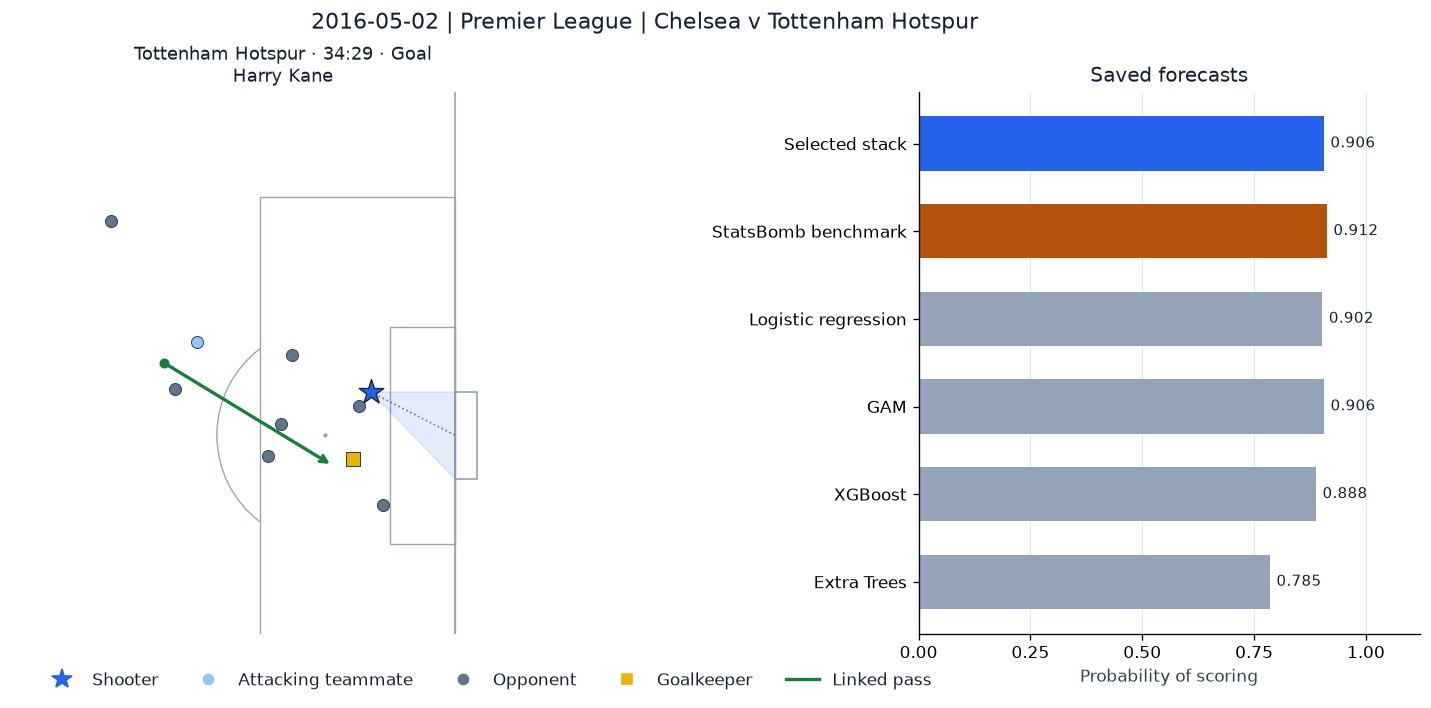

**Shot ID:** `18d44868-eb7b-42ff-89ae-686983fc34fa`. **Body part:** Left Foot. **Model minus StatsBomb:** -0.7 percentage points.

,Feature,Value,Unit
0,distance_to_goal,8.76584,pitch units
1,angle_to_goal,0.798056,radians
2,body_part,Left Foot,
3,under_pressure,True,
4,goalkeeper_visible,1,
5,goalkeeper_depth,9.4,pitch units
6,goalkeeper_line_offset,6.24697,pitch units
7,nearest_visible_defender_distance,1.70294,pitch units
8,visible_defenders_within_3,1,
9,visible_defenders_in_shot_cone,0,


In [6]:
example_figure = show_shot(DEFAULT_SHOT_ID, group="focus")


### Find nearby observed shots and compare two contexts

Candidates are from the **same match**, using the **same body part and shot type**. Rank them by
Euclidean starting-location distance in pitch units. Outcome and model xG are not used to find the
nearest neighbor. This is a browsing aid, not a controlled experiment or a causal adjustment.

,clock,team,player,outcome,body_part,location_gap,stack_identity,visible_defenders_in_shot_cone
shot_id,,,,,,,,
a2a9e676-a4a0-485e-95ad-02681d3becf1,39:13,Tottenham Hotspur,Heung-Min Son,Blocked,Left Foot,0.700,0.201,2.0
860eedaf-2465-4461-939f-f092bcda3c98,57:41,Chelsea,Gary Cahill,Goal,Left Foot,5.412,0.146,2.0
d7b66921-d479-4db6-9899-d68f864946f1,75:35,Tottenham Hotspur,Christian Dannemann Eriksen,Blocked,Left Foot,8.179,0.080,2.0
b9f531ac-ac77-4fd7-8cfa-a2f048588a91,39:10,Tottenham Hotspur,Erik Lamela,Blocked,Left Foot,9.818,0.128,1.0
0e77b468-f518-49d6-a6ce-5e3ccf134fb9,53:55,Tottenham Hotspur,Heung-Min Son,Off T,Left Foot,11.314,0.025,2.0
2fed936a-8eec-4b52-8821-8f793a397adc,23:34,Tottenham Hotspur,Heung-Min Son,Blocked,Left Foot,11.691,0.039,0.0


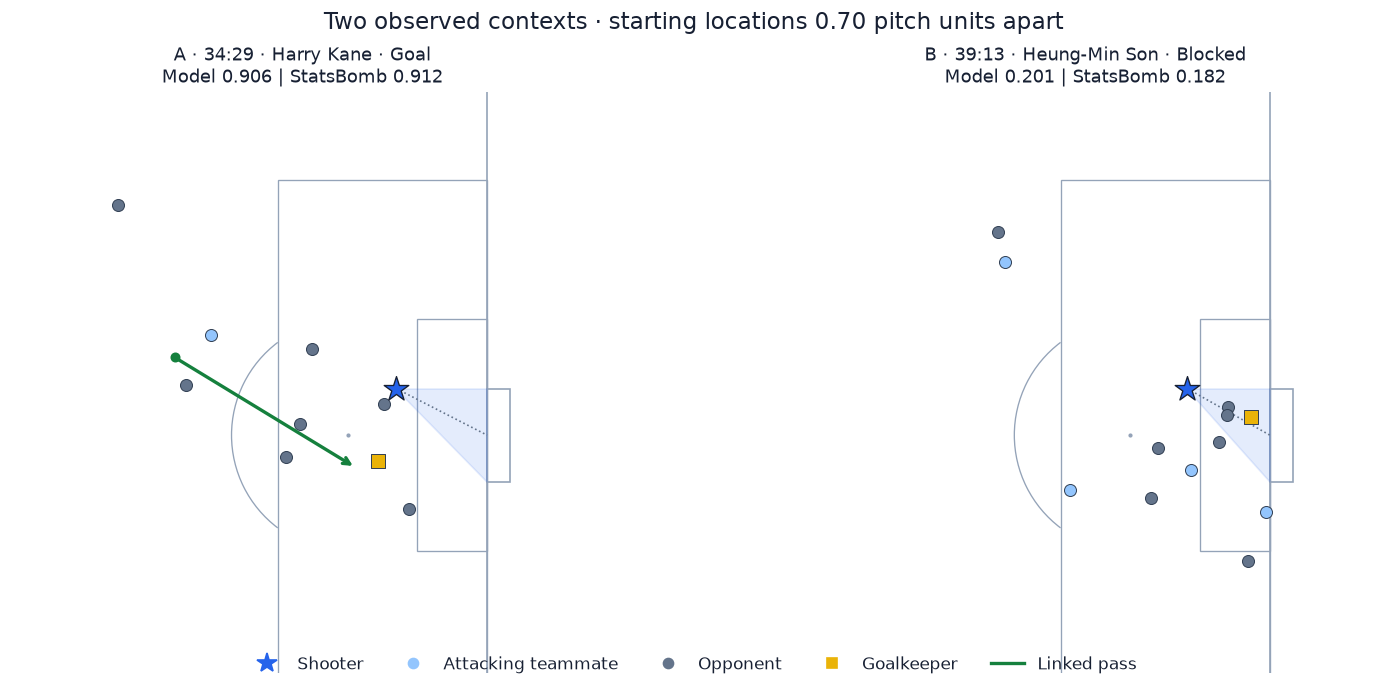

,Feature,Shot A,Shot B,Unit
0,distance_to_goal,8.76584,8.14923,pitch units
1,angle_to_goal,0.798056,0.84493,radians
2,body_part,Left Foot,Left Foot,
3,under_pressure,True,False,
4,goalkeeper_visible,1,1,
5,goalkeeper_depth,9.4,1.6,pitch units
6,goalkeeper_line_offset,6.24697,0.608646,pitch units
7,nearest_visible_defender_distance,1.70294,3.84838,pitch units
8,visible_defenders_within_3,1,0,
9,visible_defenders_in_shot_cone,0,2,


**A:** `18d44868-eb7b-42ff-89ae-686983fc34fa`. **B:** `a2a9e676-a4a0-485e-95ad-02681d3becf1`. These are separate observed shots; other model inputs can differ alongside the visible context.

In [7]:
def similar_location_shots(shot_id, limit=6):
    if limit < 1: raise ValueError("limit must be at least one")
    row = get_shot(shot_id)
    candidates = load_match(int(row["match_id"]))
    candidates = candidates.loc[(candidates.index != shot_id)
        & candidates["body_part"].eq(row["body_part"]) & candidates["shot_type"].eq(row["shot_type"])].copy()
    candidates["location_gap"] = np.hypot(candidates["shot_x"]-row["shot_x"], candidates["shot_y"]-row["shot_y"])
    return candidates.sort_values(["location_gap","event_index"]).head(limit)


def compare_shots(shot_a, shot_b, group="focus", show_cone=True, show_pass=True, view="Context zoom"):
    if shot_a == shot_b: raise ValueError("Choose two different observed shots.")
    a,b = get_shot(shot_a),get_shot(shot_b)
    fig,axes = plt.subplots(1,2,figsize=(13,5.6),layout="constrained")
    bounds = context_bounds([a,b],show_pass) if view == "Context zoom" else None
    for tag,ax,row in zip(["A","B"],axes,[a,b]):
        plot_frame(ax,row,show_cone,show_pass,view,bounds)
        ax.set_title(f"{tag} · {row['clock']} · {row['player']} · {row['outcome']}\n"
                     f"Model {row['stack_identity']:.3f} | StatsBomb {row['benchmark_statsbomb_xg']:.3f}",fontsize=11)
    gap = np.hypot(a["shot_x"]-b["shot_x"],a["shot_y"]-b["shot_y"])
    fig.suptitle(f"Two observed contexts · starting locations {gap:.2f} pitch units apart",fontsize=14)
    fig.legend(handles=FRAME_LEGEND,loc="lower center",ncol=5,frameon=False,bbox_to_anchor=(.5,-.015))
    plt.show()
    plt.close(fig)
    table = pd.DataFrame([{"Feature":name, "Shot A":feature_value(a[name]),
                          "Shot B":feature_value(b[name]), "Unit":feature_unit(name)}
                         for name in feature_names(group)])
    display(table)
    display(Markdown(f"**A:** `{shot_a}`. **B:** `{shot_b}`. These are separate observed shots; "
                     "other model inputs can differ alongside the visible context."))
    return fig

neighbors = similar_location_shots(DEFAULT_SHOT_ID)
if neighbors.empty:
    raise ValueError("The starting example has no same-body-part and same-shot-type comparison.")
COMPARISON_SHOT_ID = str(neighbors.index[0])
display(neighbors[["clock","team","player","outcome","body_part","location_gap",
                   "stack_identity","visible_defenders_in_shot_cone"]].round(3))
comparison_figure = compare_shots(DEFAULT_SHOT_ID,COMPARISON_SHOT_ID)


### Live explorer

The widgets need a live kernel and notebook widget support. Choose a **Match to load**, click
**Load match**, and use the team, player, outcome and ordering filters. The shot dropdown and
Previous/Next buttons browse that filtered set. Choose a feature group to inspect its exact raw inputs.
Select a second shot and click **Compare shots** for the paired view. **Reset** returns to the starting example.

If widgets are unavailable, the executed examples above and functions below still work:

```python
rows = load_match(DEFAULT_MATCH_ID)
show_shot(rows.index[0], group="03_goalkeeper_positioning")
compare_shots(rows.index[0], rows.index[1], group="04_defensive_pressure")
```

Changing selectors does not change model inputs or recompute probabilities. There are no counterfactual controls.

In [8]:
def build_explorer():
    try:
        import ipywidgets as widgets
    except ImportError:
        display(Markdown("Install `ipywidgets` in this kernel to enable selectors. `show_shot` and `compare_shots` remain available."))
        return None

    wide = {"width":"98%"}
    match_choice = widgets.Dropdown(options=[(match_label(mid),int(mid)) for mid in match_catalog.index],
                                    value=DEFAULT_MATCH_ID,description="Match to load",layout=wide,
                                    style={"description_width":"initial"})
    load_button = widgets.Button(description="Load match",button_style="primary")
    reset_button = widgets.Button(description="Reset")
    team = widgets.Dropdown(options=["All teams"],description="Team")
    player = widgets.Dropdown(options=["All players"],description="Player")
    outcome = widgets.Dropdown(options=["All shots","Goals","Non-goals"],description="Outcome")
    ordering = widgets.Dropdown(options=["Chronological","Highest xG","Largest benchmark gap"],description="Order")
    shot = widgets.Dropdown(options=[],description="Shot",layout=wide)
    second = widgets.Dropdown(options=[],description="Compare with",layout=wide,
                              style={"description_width":"initial"})
    group = widgets.Dropdown(options=[("Key context","focus"),*[(v,k) for k,v in GROUP_LABELS.items()],("All raw features","all")],
                             value="focus",description="Features",layout=wide)
    cone = widgets.Checkbox(value=True,description="Show goal cone",indent=False)
    assist = widgets.Checkbox(value=True,description="Show linked pass",indent=False)
    view = widgets.Dropdown(options=["Context zoom","Full pitch"],description="Pitch view")
    previous = widgets.Button(description="Previous")
    following = widgets.Button(description="Next")
    compare_button = widgets.Button(description="Compare shots")
    status = widgets.HTML()
    output = widgets.Output()
    state = {"rows":load_match(DEFAULT_MATCH_ID),"busy":False,"filtered_ids":[]}

    def label(row):
        return f"{row['clock']} | {row['team']} | {row['player']} | {row['outcome']} | xG {row['stack_identity']:.3f}"

    def render(_=None):
        if state["busy"]: return
        with output:
            output.clear_output(wait=True)
            if shot.value is None:
                display(Markdown("No shots match these filters. Widen the selection or reset."))
            else:
                show_shot(shot.value,group.value,cone.value,assist.value,view.value)

    def refresh(_=None):
        if state["busy"]: return
        old_shot = shot.value
        old_player = player.value
        state["busy"] = True
        try:
            rows = state["rows"]
            if team.value != "All teams": rows = rows.loc[rows["team"].eq(team.value)]
            player.options = ["All players",*sorted(rows["player"].unique())]
            player.value = old_player if old_player in player.options else "All players"
            if player.value != "All players": rows = rows.loc[rows["player"].eq(player.value)]
            if outcome.value != "All shots": rows = rows.loc[rows["is_goal"].eq(outcome.value=="Goals")]
            if ordering.value == "Highest xG": rows = rows.sort_values(["stack_identity","event_index"],ascending=[False,True])
            elif ordering.value == "Largest benchmark gap":
                rows = rows.assign(_gap=(rows["stack_identity"]-rows["benchmark_statsbomb_xg"]).abs()).sort_values(["_gap","event_index"],ascending=[False,True])
            else: rows = rows.sort_values("event_index")
            state["filtered_ids"] = list(rows.index)
            shot.options = [(label(row),sid) for sid,row in rows.iterrows()] or [("No matching shots",None)]
            shot.value = old_shot if old_shot in rows.index else (rows.index[0] if len(rows) else None)
            others = state["rows"].loc[state["rows"].index != shot.value]
            old_second = second.value
            second.options = [(label(row),sid) for sid,row in others.iterrows()] or [("No comparison shot",None)]
            second.value = old_second if old_second in others.index else (others.index[0] if len(others) else None)
            previous.disabled = following.disabled = len(rows)<2
            compare_button.disabled = shot.value is None or second.value is None
        finally:
            state["busy"] = False
        render()

    def selection_changed(change):
        if state["busy"]: return
        state["busy"] = True
        try:
            old_second = second.value
            others = state["rows"].loc[state["rows"].index != shot.value]
            second.options = [(label(row),sid) for sid,row in others.iterrows()] or [("No comparison shot",None)]
            second.value = old_second if old_second in others.index else (others.index[0] if len(others) else None)
            compare_button.disabled = shot.value is None or second.value is None
        finally:
            state["busy"] = False
        render()

    def load_selected(_=None):
        load_button.disabled = True
        try:
            new_rows = load_match(match_choice.value)
            state["busy"] = True
            state["rows"] = new_rows
            team.options = ["All teams",*sorted(new_rows["team"].unique())]
            team.value,player.value,outcome.value = "All teams","All players","All shots"
            ordering.value = "Chronological"
            status.value = "Loaded " + html.escape(match_label(match_choice.value))
        except Exception as error:
            status.value = "Could not load selected match: " + html.escape(str(error)) + ". The previous match remains available."
        finally:
            state["busy"] = False
            load_button.disabled = False
        refresh()

    def move(delta):
        ids = state["filtered_ids"]
        if shot.value in ids: shot.value = ids[(ids.index(shot.value)+delta)%len(ids)]

    def compare(_):
        if shot.value is None or second.value is None: return
        with output:
            output.clear_output(wait=True)
            compare_shots(shot.value,second.value,group.value,cone.value,assist.value,view.value)

    def reset(_):
        state["busy"] = True
        try:
            match_choice.value,group.value,cone.value,assist.value = DEFAULT_MATCH_ID,"focus",True,True
            view.value = "Context zoom"
        finally:
            state["busy"] = False
        load_selected()
        shot.value = DEFAULT_SHOT_ID
        second.value = COMPARISON_SHOT_ID

    for control in [team,player,outcome,ordering]: control.observe(refresh,names="value")
    for control in [group,cone,assist,view]: control.observe(render,names="value")
    shot.observe(selection_changed,names="value")
    load_button.on_click(load_selected)
    reset_button.on_click(reset)
    previous.on_click(lambda _:move(-1))
    following.on_click(lambda _:move(1))
    compare_button.on_click(compare)
    panel = widgets.VBox([match_choice,widgets.HBox([load_button,reset_button]),status,
                          widgets.HBox([team,player]),widgets.HBox([outcome,ordering]),shot,
                          widgets.HBox([previous,following]),group,widgets.HBox([cone,assist]),view,
                          second,compare_button,output])
    display(panel)
    state["busy"] = True
    team.options = ["All teams",*sorted(state["rows"]["team"].unique())]
    state["busy"] = False
    refresh()
    shot.value = DEFAULT_SHOT_ID
    second.value = COMPARISON_SHOT_ID
    status.value = "Loaded " + html.escape(match_label(DEFAULT_MATCH_ID))
    return {"panel":panel,"state":state,"match":match_choice,"load":load_button,"team":team,"player":player,
            "outcome":outcome,"ordering":ordering,"shot":shot,"second":second,"group":group,
            "cone":cone,"assist":assist,"previous":previous,"next":following,
            "view":view,
            "compare":compare_button,"reset":reset_button,"output":output,"status":status}

explorer = build_explorer()


## Checks

The notebook verifies file hashes and one-to-one routing before plotting. Public labels and freeze
frames are checked when a match is loaded. The starting comparison below reconciles the displayed
probabilities, location gap and shot-cone counts directly to the saved checkpoint.

In [9]:
a,b = get_shot(DEFAULT_SHOT_ID),get_shot(COMPARISON_SHOT_ID)
assert a["body_part"] == b["body_part"] and a["shot_type"] == b["shot_type"]
assert int(a["match_id"]) == int(b["match_id"]) == DEFAULT_MATCH_ID
assert np.isclose(a["stack_identity"],predictions.set_index("shot_id").at[DEFAULT_SHOT_ID,"stack_identity"],rtol=0,atol=0)
assert set(context_table(DEFAULT_SHOT_ID,"all")["Feature"]) == set(raw_features)
assert len(context_table(DEFAULT_SHOT_ID,"all")) == 67
print(f"A: {a['player']} at {a['clock']} | {a['stack_identity']:.3f} xG | {a['visible_defenders_in_shot_cone']:g} defenders in cone")
print(f"B: {b['player']} at {b['clock']} | {b['stack_identity']:.3f} xG | {b['visible_defenders_in_shot_cone']:g} defenders in cone")
print("Checks passed: frozen hashes, test coverage, shot routing, event agreement, pass linkage and 67-feature inspection.")


A: Harry Kane at 34:29 | 0.906 xG | 0 defenders in cone
B: Heung-Min Son at 39:13 | 0.201 xG | 2 defenders in cone
Checks passed: frozen hashes, test coverage, shot routing, event agreement, pass linkage and 67-feature inspection.


## Next steps

Use the explorer to find similar locations with different goalkeeper positions, visible blockers or
passing situations. Check the complete feature group when a summary value is unavailable. A large
model-versus-StatsBomb difference identifies a case to inspect, not proof that either prediction is wrong.
These test shots must not guide new tuning presented as independent validation.

**Sources:** [StatsBomb Open Data](https://github.com/hudl/open-data), pinned to
`3bfbffe1de5750ebd47d770be0bb924a10cde54f`; the project's frozen `test_model_predictions.parquet`,
`features_stage_08.parquet`, `features_stage_08.json` and `matches.parquet`.
Credit StatsBomb when sharing derived figures. No original artifacts are modified by this notebook.